In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
from pathlib import Path

split_dir = Path("/content/drive/MyDrive/NLP/splits")

train_df = pd.read_csv(split_dir / "train.csv", keep_default_na=False)
val_df = pd.read_csv(split_dir / "validation.csv", keep_default_na=False)
test_df = pd.read_csv(split_dir / "test.csv", keep_default_na=False)

X_train = train_df["review_comment"].to_numpy(dtype=str)
X_val = val_df["review_comment"].to_numpy(dtype=str)
X_test = test_df["review_comment"].to_numpy(dtype=str)

y_train = train_df["label"].to_numpy(dtype="int32")
y_val = val_df["label"].to_numpy(dtype="int32")
y_test = test_df["label"].to_numpy(dtype="int32")

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

BATCH_SIZE = 64
MAX_TOKENS = 15000

def make_dataset(texts, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((texts, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(texts),
            seed=42
        )

    return ds.batch(BATCH_SIZE).prefetch(1)

In [ ]:
train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

In [ ]:
vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=150
)

adapt_ds = tf.data.Dataset.from_tensor_slices(X_train).batch(BATCH_SIZE)
vectorizer.adapt(adapt_ds)

In [ ]:
model = models.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    vectorizer,
    layers.Embedding(
        input_dim=vectorizer.vocabulary_size(),
        output_dim=128,
    ),
    layers.Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu"
    ),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 150)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 150, 128)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 148, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,969,925 (7.51 MB)

 Trainable params: 1,969,925 (7.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print(class_weights)

{0: 0.9406764333514198, 1: 3.8355457227138645, 2: 2.3033658104517274, 3: 1.3694049499736705, 4: 0.39811696264543783}


In [ ]:
gentle_weights = {
    label: float(np.sqrt(weight))
    for label, weight in class_weights.items()
}

print(gentle_weights)

{0: 0.9698847526131236, 1: 1.958454932520497, 2: 1.5176843579782087, 3: 1.1702157706908887, 4: 0.6309651041424065}


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=gentle_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Epoch 1/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6475 - loss: 1.0888 - val_accuracy: 0.6795 - val_loss: 0.9029
Epoch 2/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.7023 - loss: 0.9162 - val_accuracy: 0.6838 - val_loss: 0.8745
Epoch 3/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7378 - loss: 0.8046 - val_accuracy: 0.6638 - val_loss: 0.9062
Epoch 4/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7811 - loss: 0.6775 - val_accuracy: 0.6643 - val_loss: 0.9448
Epoch 5/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8168 - loss: 0.5578 - val_accuracy: 0.6458 - val_loss: 1.0340


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, mean_absolute_error

# Validation predictions while developing the model
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["Score 1", "Score 2", "Score 3", "Score 4", "Score 5"],
    zero_division=0
))

print("MAE:", mean_absolute_error(y_val, y_pred))

102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
              precision    recall  f1-score   support

     Score 1       0.68      0.86      0.76      1383
     Score 2       0.18      0.13      0.15       339
     Score 3       0.30      0.24      0.26       564
     Score 4       0.36      0.17      0.23       950
     Score 5       0.81      0.89      0.85      3266

    accuracy                           0.68      6502
   macro avg       0.46      0.46      0.45      6502
weighted avg       0.64      0.68      0.65      6502

MAE: 0.48031374961550294


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error

probs = model.predict(val_ds, verbose=0)
actual = np.asarray(y_val).ravel() + 1

predictions = {
    "Most probable star": probs.argmax(axis=1) + 1,
    "Median star": (probs.cumsum(axis=1) < 0.5).sum(axis=1) + 1,
}

rows = []
for rule, pred in predictions.items():
    actual_two = actual == 2
    predicted_two = pred == 2
    correct_two = (actual_two & predicted_two).sum()

    rows.append({
        "Rule": rule,
        "Accuracy": accuracy_score(actual, pred),
        "Macro-F1": f1_score(actual, pred, labels=[1, 2, 3, 4, 5],
                             average="macro", zero_division=0),
        "MAE": mean_absolute_error(actual, pred),
        "Two-star precision": correct_two / max(predicted_two.sum(), 1),
        "Two-star recall": correct_two / actual_two.sum(),
        "Within one star": (np.abs(actual - pred) <= 1).mean(),
    })

display(pd.DataFrame(rows).set_index("Rule").round(4))

,Accuracy,Macro-F1,MAE,Two-star precision,Two-star recall,Within one star
Rule,,,,,,
Most probable star,0.6838,0.4511,0.4803,0.1833,0.1298,0.8902
Median star,0.6203,0.4584,0.5043,0.1589,0.3805,0.9037


In [ ]:
from pathlib import Path

model_dir = Path("/content/drive/MyDrive/NLP/models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "review_score_model.keras"

model.save(str(model_path))

print("Model saved:", model_path)

Model saved: /content/drive/MyDrive/NLP/models/review_score_model.keras


In [ ]:
weight_by_label = tf.constant(
    [gentle_weights[i] for i in range(5)], dtype=tf.float32
)

def ordinal_targets(y):
    labels = tf.reshape(tf.cast(y, tf.int32), [-1, 1])
    return tf.cast(labels > tf.range(4), tf.float32)

def ordinal_train_batch(text, y):
    labels = tf.reshape(tf.cast(y, tf.int32), [-1])
    return text, ordinal_targets(labels), tf.gather(weight_by_label, labels)

ordinal_train_ds = train_ds.map(ordinal_train_batch)
ordinal_val_ds = val_ds.map(lambda text, y: (text, ordinal_targets(y)))

In [ ]:
tf.keras.utils.set_random_seed(42)

text = tf.keras.Input(shape=(), dtype=tf.string)
x = vectorizer(text)
x = layers.Embedding(vectorizer.vocabulary_size(), 128)(x)
x = layers.Conv1D(128, 3, activation="relu")(x)
x = layers.GlobalMaxPooling1D()(x)
x = layers.Dropout(0.3)(x)
stars = layers.Dense(5, activation="softmax")(x)

threshold_matrix = (
    np.arange(1, 6)[:, None] > np.arange(1, 5)[None, :]
).astype("float32")

thresholds = layers.Dense(
    4,
    use_bias=False,
    trainable=False,
    kernel_initializer=tf.keras.initializers.Constant(threshold_matrix)
)(stars)

ordinal_model = tf.keras.Model(text, thresholds)
ordinal_predictor = tf.keras.Model(text, stars)

ordinal_model.compile(optimizer="adam", loss="binary_crossentropy")

ordinal_history = ordinal_model.fit(
    ordinal_train_ds,
    validation_data=ordinal_val_ds,
    epochs=50,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        )
    ]
)

Epoch 1/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.3571 - val_loss: 0.2936
Epoch 2/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.2859 - val_loss: 0.2854
Epoch 3/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.2496 - val_loss: 0.2972
Epoch 4/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2170 - val_loss: 0.3121
Epoch 5/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1875 - val_loss: 0.3325


In [ ]:
actual = np.asarray(y_val).ravel() + 1
rows = []

for name, predictor in [
    ("Original CNN", model),
    ("Ordinal CNN", ordinal_predictor),
]:
    probabilities = predictor.predict(val_ds, verbose=0)
    predicted = probabilities.argmax(axis=1) + 1

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Macro-F1": f1_score(actual, predicted, labels=[1, 2, 3, 4, 5],
                             average="macro", zero_division=0),
        "MAE": mean_absolute_error(actual, predicted),
        "Two-star recall": np.mean(predicted[actual == 2] == 2),
        "Within one star": np.mean(np.abs(actual - predicted) <= 1),
    })

display(pd.DataFrame(rows).set_index("Model").round(4))

,Accuracy,Macro-F1,MAE,Two-star recall,Within one star
Model,,,,,
Original CNN,0.6838,0.4511,0.4803,0.1298,0.8902
Ordinal CNN,0.6916,0.4306,0.4780,0.0059,0.8867


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, mean_absolute_error

# Test predictions for the original Embedding CNN
y_pred_test = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(
    y_test,
    y_pred_test,
    labels=[0, 1, 2, 3, 4],
    target_names=["Score 1", "Score 2", "Score 3", "Score 4", "Score 5"],
    zero_division=0
))

print("Test MAE:", mean_absolute_error(y_test, y_pred_test))

127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
              precision    recall  f1-score   support

     Score 1       0.68      0.86      0.76      1728
     Score 2       0.20      0.13      0.16       423
     Score 3       0.28      0.24      0.26       706
     Score 4       0.35      0.19      0.25      1187
     Score 5       0.81      0.88      0.84      4083

    accuracy                           0.68      8127
   macro avg       0.46      0.46      0.45      8127
weighted avg       0.64      0.68      0.65      8127

Test MAE: 0.4924326319675157


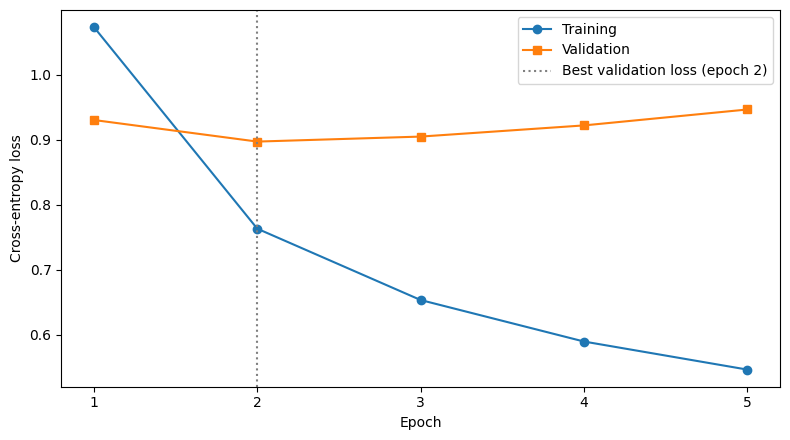

In [1]:
import numpy as np
import matplotlib.pyplot as plt

train_loss = [1.0736, 0.7633, 0.6535, 0.5896, 0.5464]
val_loss = [0.9306, 0.8974, 0.9051, 0.9223, 0.9468]

epochs = np.arange(1, len(train_loss) + 1)
best_epoch = int(np.argmin(val_loss)) + 1

plt.figure(figsize=(8, 4.5))

plt.plot(
    epochs, train_loss,
    marker="o", label="Training"
)
plt.plot(
    epochs, val_loss,
    marker="s", label="Validation"
)
plt.axvline(
    best_epoch,
    color="gray",
    linestyle=":",
    label=f"Best validation loss (epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()
plt.show()